# Stro-7 module (top 10 genes) scored in mouse (X-Mens), spatial by timepoint

Score the top-10 genes of the Stro-7 / C7-fibroblast module — mapped to mouse orthologs —
on the X-Mens data, and plot the module score spatially for each `timepoint`.

Two spots need your input (both are inspected first, so you can fill them from what prints):
1. **Which xlsx + sheet** holds the Stro-7 markers, and how "top 10" is defined (row order vs a score column).
2. **Ortholog resolution** — the default assumes the mouse object uses plain mouse symbols
   (Title-case, e.g. `Cxcl12`), matched case-insensitively to the human symbols. Confirm from the
   var-name inspection.


## 0. Imports

In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.sparse import issparse
import warnings; warnings.filterwarnings("ignore")
sc.settings.verbosity = 1


## 1. Load the mouse object + inspect

In [2]:
mm = sc.read_h5ad(
    "/n/netscratch/eddy_lab/Everyone/nhilgert/2026_08_21_Cevrim_XMens_All_Cells.h5ad"
)
print(mm)
print("\nobs columns:", list(mm.obs.columns))
print("layers:", list(mm.layers.keys()))
print("timepoints:", sorted(mm.obs["timepoint"].unique()) if "timepoint" in mm.obs else "NO timepoint col")
print("\nfirst 20 var_names (check case convention):")
print(list(mm.var_names[:20]))


AnnData object with n_obs × n_vars = 57033 × 33698
    obs: 'sample', 'cell_barcode', 'timepoint', 'coarse_refined', 'fine_refined', 'origin_lineage', 'cell_type', 'cell_subtype', 'auc_MMy', 'auc_MD', 'auc_VSZ', 'auc_FMI', 'auc_C', 'auc_PDZ', 'auc_TDZ', 'auc_SDZ', 'auc_udStr', 'auc_Glan', 'auc_AMMy', 'x_um_dbscan', 'y_um_dbscan'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'ribo', 'hb', 'mito', 'highly_variable', 'highly_variable_rank', 'highly_variable_nbatches'
    uns: 'hvg', 'log1p', 'neighbors_scVI_100', 'timepoint_colors', 'umap'
    obsm: 'X_scVI', 'X_umap_scVI', 'spatial'
    layers: 'counts'
    obsp: 'neighbors_scVI_100_connectivities', 'neighbors_scVI_100_distances'

obs columns: ['sample', 'cell_barcode', 'timepoint', 'coarse_refined', 'fine_refined', 'origin_lineage', 'cell_type', 'cell_subtype', 'auc_MMy', 'auc_MD', 'auc_VSZ', 'auc_FMI', 'auc_C', 'auc_PDZ', 'auc_TDZ', 'auc_SDZ', 'auc_udStr', 'auc_Glan', 'auc_AMMy', 'x_um_dbscan', 'y_um_dbscan']
layers: ['counts']

### 1.1 Set the key variables
Fill these from section 1 output. Mouse spatial keys / timepoint values may differ from human.


In [3]:
COUNTS_LAYER = "counts"        # raw counts, for a clean log1p (set None to use .X)
X_KEY        = "x_um_dbscan"   # spatial x  (CHANGE if named differently)
Y_KEY        = "y_um_dbscan"   # spatial y
TP_COL       = "timepoint"

# per-timepoint rotation (degrees, CCW). Fill in once you see the timepoint values +
# how each puck is oriented; leave empty for no rotation.
ROTATE_DEG   = {}              # e.g. {"1dpi": 0, "3dpi": 90, ...}

for c in (X_KEY, Y_KEY, TP_COL):
    assert c in mm.obs, f"{c!r} not in obs: {list(mm.obs.columns)}"
if COUNTS_LAYER is not None:
    assert COUNTS_LAYER in mm.layers, f"{COUNTS_LAYER!r} not in layers: {list(mm.layers)}"
print("keys OK | timepoints:", sorted(mm.obs[TP_COL].unique()))


keys OK | timepoints: ['1_dpi_early', '1_dpi_late', '2_dpi', '3_dpi', '4_dpi_bleeding', 'uninduced']


## 2. Get the top-10 Stro-7 module genes (human symbols) from the xlsx

**CHANGE `XLSX` and `SHEET`** to the file/sheet holding the Stro-7 markers. The cell prints the
sheet's columns and first rows so you can confirm the gene column and whether the rows are already
rank-ordered (if there's a score/logFC column, we sort by it; otherwise we take the first 10 as listed).


In [14]:
XLSX  = "pnas.2404775121.sd06.xlsx"     # CHANGE: the supplement with per-cluster markers
SHEET = "6C Stro markers"               # CHANGE: sheet holding stromal markers
STRO7_LABEL_CONTAINS = "7"              # how to pick the Stro-7 cluster within the sheet
TOP_N = 25

xl = pd.ExcelFile(XLSX)
print("sheets:", xl.sheet_names)
raw = pd.read_excel(XLSX, sheet_name=SHEET, header=2)   # header row may differ; check below
raw.columns = [str(c).strip() for c in raw.columns]
print("\ncolumns:", list(raw.columns))
display(raw.head(8))


sheets: ['6A Major cell type DEGs', '6B Blood endo markers', '6C Stro markers', '6D Non-cil Epi markers', '6E Imm markers']

columns: ['p_val', 'avg_log2FC', 'pct.1', 'pct.2', 'p_val_adj', 'cluster', 'gene']


,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
0,0.0,2.846047,0.883,0.278,0.0,1_PV MYH11 FOXC1 hi CTGF lo,KLF2
1,0.0,2.649051,0.854,0.089,0.0,1_PV MYH11 FOXC1 hi CTGF lo,MUSTN1
2,0.0,2.593680,0.982,0.712,0.0,1_PV MYH11 FOXC1 hi CTGF lo,C11orf96
3,0.0,2.534343,0.916,0.346,0.0,1_PV MYH11 FOXC1 hi CTGF lo,CRIP1
4,0.0,2.489214,0.958,0.437,0.0,1_PV MYH11 FOXC1 hi CTGF lo,ADIRF
5,0.0,2.406103,0.692,0.206,0.0,1_PV MYH11 FOXC1 hi CTGF lo,MT1M
6,0.0,2.366438,0.972,0.749,0.0,1_PV MYH11 FOXC1 hi CTGF lo,HSPA1A
7,0.0,2.286803,0.866,0.244,0.0,1_PV MYH11 FOXC1 hi CTGF lo,C12orf75


### 2.1 Extract the ranked top-10 for Stro-7
Adjust the column names (`cluster`, `gene`, and an optional score column) to match 2.0's output.


In [15]:
CLUSTER_COL = "cluster"     # CHANGE to the cluster-label column
GENE_COL    = "gene"        # CHANGE to the gene-symbol column
SCORE_COL   = None          # e.g. "avg_log2FC" or "score" to sort by; None = keep sheet order

df = raw.dropna(subset=[GENE_COL]).copy()
df[GENE_COL] = df[GENE_COL].astype(str).str.strip().str.upper()

# pick the Stro-7 cluster rows
mask = df[CLUSTER_COL].astype(str).str.contains(STRO7_LABEL_CONTAINS, na=False)
stro7 = df[mask].copy()
print(f"Stro-7 rows: {len(stro7)}  (cluster labels seen: {stro7[CLUSTER_COL].unique()[:5]})")

if SCORE_COL and SCORE_COL in stro7.columns:
    stro7 = stro7.sort_values(SCORE_COL, ascending=False)

human_top10 = stro7[GENE_COL].drop_duplicates().head(TOP_N).tolist()
print(f"\ntop {TOP_N} Stro-7 genes (human symbols):")
print(human_top10)


Stro-7 rows: 144  (cluster labels seen: ['3_PV STEAP7' '3_PV STEAP17' '3_PV STEAP27' '3_PV STEAP37' '3_PV STEAP47'])

top 25 Stro-7 genes (human symbols):
['HIGD1B', 'GEM', 'MEF2C', 'KCNE4', 'NDRG2', 'CAMK2N1', 'MIR4435-2HG', 'OAZ2', 'SEPT7', 'COL4A2', 'GAS6', 'IGFBP6', 'EDNRB', 'ADAMTS4', 'PDGFRB', 'DLC1', 'BGN', 'ID3', 'APOD', 'C7', 'DCN', 'CCDC80', 'ADH1B', 'GSN', 'SERPINF1']


## 3. Map to mouse orthologs

Default: match human UPPER-case symbols to the mouse object's var names case-insensitively
(handles the human `CXCL12` -> mouse `Cxcl12` convention). Prints the mapping so you can see
what mapped and what's genuinely absent. If your object uses an ortholog table or `mm_` prefixes
instead, replace `resolve` accordingly.


In [16]:
mm_lut = pd.Series(mm.var_names.to_numpy(), index=mm.var_names.str.upper())
mm_lut = mm_lut[~mm_lut.index.duplicated()]
resolve = lambda g: mm_lut.get(g.upper())

pairs = {g: resolve(g) for g in human_top10}
print("human -> mouse ortholog:")
for h, m in pairs.items():
    print(f"   {h:12s} -> {m}")

mapped = {k: v for k, v in pairs.items() if v is not None}
missing = [k for k, v in pairs.items() if v is None]
print(f"\nmapped {len(mapped)}/{len(human_top10)}; genuinely absent in mouse: {missing}")
mouse_genes = list(mapped.values())
assert len(mouse_genes) >= 3, "too few genes mapped — check the ortholog resolution / var-name case"


human -> mouse ortholog:
   HIGD1B       -> Higd1b
   GEM          -> Gem
   MEF2C        -> Mef2c
   KCNE4        -> Kcne4
   NDRG2        -> Ndrg2
   CAMK2N1      -> Camk2n1
   MIR4435-2HG  -> None
   OAZ2         -> Oaz2
   SEPT7        -> None
   COL4A2       -> Col4a2
   GAS6         -> Gas6
   IGFBP6       -> Igfbp6
   EDNRB        -> Ednrb
   ADAMTS4      -> Adamts4
   PDGFRB       -> Pdgfrb
   DLC1         -> Dlc1
   BGN          -> Bgn
   ID3          -> Id3
   APOD         -> Apod
   C7           -> C7
   DCN          -> Dcn
   CCDC80       -> Ccdc80
   ADH1B        -> None
   GSN          -> Gsn
   SERPINF1     -> Serpinf1

mapped 22/25; genuinely absent in mouse: ['MIR4435-2HG', 'SEPT7', 'ADH1B']


## 4. Build log1p + score the module

In [17]:
if COUNTS_LAYER is not None:
    mm.layers["log1p"] = mm.layers[COUNTS_LAYER].copy()
    mm.X = mm.layers["log1p"]
    sc.pp.normalize_total(mm, target_sum=1e4)
    sc.pp.log1p(mm)
    mm.layers["log1p"] = mm.X.copy()
else:
    mm.layers["log1p"] = mm.X.copy()   # assume .X already log-normalised

sc.tl.score_genes(mm, mouse_genes, score_name="stro7_module",
                  ctrl_size=50, use_raw=False, random_state=0)
print(mm.obs["stro7_module"].describe().round(3))


count    57033.000
mean        -0.009
std          0.141
min         -0.326
25%         -0.116
50%         -0.028
75%          0.078
max          0.878
Name: stro7_module, dtype: float64


## 5. Spatial plot of the module score, per timepoint

Signed `score_genes` output -> 0-centered diverging map, symmetric robust (1-99 pct) scale
shared across timepoints. High-|score| cells drawn on top.


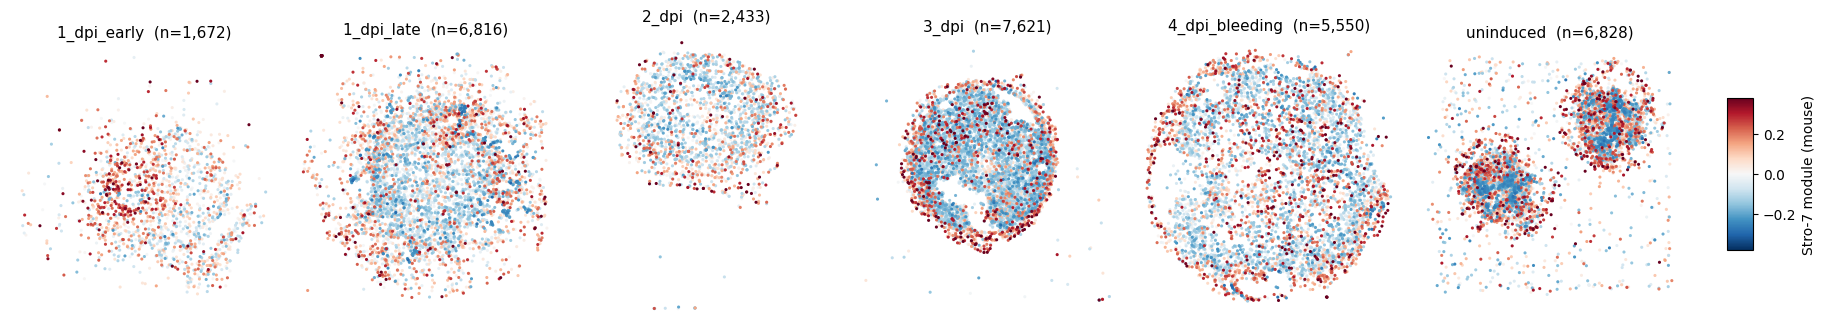

Saved: xmens_stro7_module_spatial.png


In [18]:
def rotate(x, y, deg, cx=None, cy=None):
    cx = x.mean() if cx is None else cx
    cy = y.mean() if cy is None else cy
    t  = np.deg2rad(deg)
    return (cx + (x - cx)*np.cos(t) - (y - cy)*np.sin(t),
            cy + (x - cx)*np.sin(t) + (y - cy)*np.cos(t))

timepoints = sorted(mm.obs[TP_COL].unique())
vals = mm.obs["stro7_module"].to_numpy(float)
lim  = np.nanpercentile(np.abs(vals[np.isfinite(vals)]), 99)

fig, axes = plt.subplots(1, len(timepoints), figsize=(3.6*len(timepoints), 3.8))
axes = np.atleast_1d(axes).ravel()
for ax, tp in zip(axes, timepoints):
    d = mm.obs.loc[mm.obs[TP_COL] == tp, [X_KEY, Y_KEY, "stro7_module"]]
    x = d[X_KEY].to_numpy(float); y = d[Y_KEY].to_numpy(float); s = d["stro7_module"].to_numpy(float)
    m = np.isfinite(x) & np.isfinite(y) & np.isfinite(s)
    x, y, s = x[m], y[m], s[m]
    x, y = rotate(x, y, ROTATE_DEG.get(tp, 0))
    o = np.argsort(np.abs(s))
    pts = ax.scatter(x[o], y[o], c=s[o], cmap="RdBu_r", vmin=-lim, vmax=lim,
                     s=5, linewidths=0, rasterized=True)
    ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_axis_off()
    ax.set_title(f"{tp}  (n={m.sum():,})", fontsize=11)
fig.subplots_adjust(right=0.9, wspace=0.05)
cax = fig.add_axes([0.92, 0.3, 0.012, 0.4])
fig.colorbar(pts, cax=cax, label="Stro-7 module (mouse)")
fig.savefig("xmens_stro7_module_spatial.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved: xmens_stro7_module_spatial.png")


resolved C7 -> C7
C7: 1.4% of cells express it; max log1p = 3.91


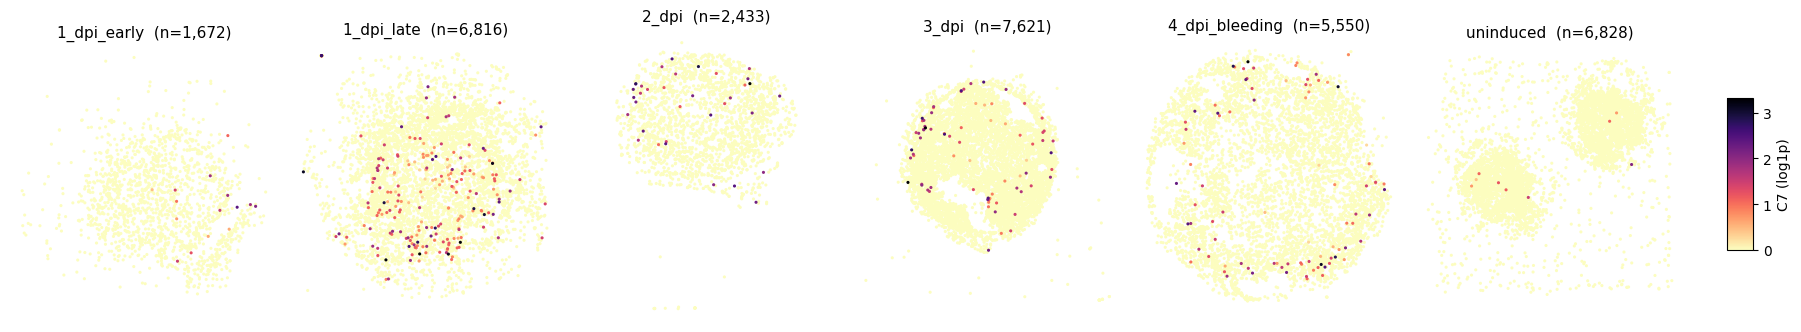

In [19]:
# --- Plot C7 expression spatially, per timepoint (mouse) ---
import numpy as np, matplotlib.pyplot as plt
from scipy.sparse import issparse

GENE = "C7"

# resolve the gene name case-insensitively (mouse may write it differently)
_lut = pd.Series(mm.var_names.to_numpy(), index=mm.var_names.str.upper())
_lut = _lut[~_lut.index.duplicated()]
gene_id = _lut.get(GENE.upper())
assert gene_id is not None, f"{GENE} not in mm.var_names — check the mouse symbol"
print(f"resolved {GENE} -> {gene_id}")

# pull log1p expression for the gene
j = mm.var_names.get_loc(gene_id)
_M = mm.layers["log1p"] if "log1p" in mm.layers else mm.X
_col = _M[:, j]
expr = (_col.toarray().ravel() if issparse(_col) else np.asarray(_col).ravel()).astype(float)
mm.obs["_gene_expr"] = expr
print(f"{gene_id}: {(expr > 0).mean()*100:.1f}% of cells express it; max log1p = {expr.max():.2f}")

# sparse, non-negative -> sequential scale, robust max over expressing cells, hi on top
timepoints = sorted(mm.obs[TP_COL].unique())
_pos = expr[expr > 0]
vmax = np.percentile(_pos, 99) if _pos.size else 1.0

fig, axes = plt.subplots(1, len(timepoints), figsize=(3.6*len(timepoints), 3.8))
axes = np.atleast_1d(axes).ravel()
for ax, tp in zip(axes, timepoints):
    d = mm.obs.loc[mm.obs[TP_COL] == tp, [X_KEY, Y_KEY, "_gene_expr"]]
    x = d[X_KEY].to_numpy(float); y = d[Y_KEY].to_numpy(float); s = d["_gene_expr"].to_numpy(float)
    m = np.isfinite(x) & np.isfinite(y)
    x, y, s = x[m], y[m], s[m]
    x, y = rotate(x, y, ROTATE_DEG.get(tp, 0))
    o = np.argsort(s)                       # expressing cells drawn on top
    pts = ax.scatter(x[o], y[o], c=s[o], cmap="magma_r", vmin=0, vmax=vmax,
                     s=5, linewidths=0, rasterized=True)
    ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_axis_off()
    ax.set_title(f"{tp}  (n={m.sum():,})", fontsize=11)
fig.subplots_adjust(right=0.9, wspace=0.05)
cax = fig.add_axes([0.92, 0.3, 0.012, 0.4])
fig.colorbar(pts, cax=cax, label=f"{gene_id} (log1p)")
fig.savefig(f"xmens_{gene_id}_spatial.png", dpi=300, bbox_inches="tight")
plt.show()